# Etap 2 — Struktura zbiorów danych, klasyfikacja atrybutów i podstawowa analiza statystyczna

**Rezultat etapu (wg wytycznych):** opracowany zbiór danych wraz z charakterystyką struktury, klasyfikacją atrybutów,
relacjami między nimi, analizą statystyczną, porównaniem technik imputacji oraz wizualizacjami.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent))
from src.utils import *  # ścieżki, wczytywanie danych, styl wykresów

set_plot_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

In [2]:
sales = load_apartments("sale")
rent = load_apartments("rent")
cost_2024 = load_cost_2024()
cost_long = load_cost_longitudinal()

# pomocniczo: cena za m² — główna miara porównawcza w całym projekcie
sales["price_per_m2"] = sales["price"] / sales["squareMeters"]
rent["price_per_m2"] = rent["price"] / rent["squareMeters"]
print(sales.shape, rent.shape, cost_2024.shape, cost_long.shape)

(195568, 31) (70847, 31) (295, 19) (2745, 22)


## 2.1 Struktura zbioru ofert

Oba pliki ofertowe (sprzedaż i najem) mają **identyczną strukturę 28 kolumn** — różni się tylko znaczenie kolumny `price`.

In [3]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 195568 entries, 0 to 195567
Data columns (total 31 columns):
 #   Column                Non-Null Count   Dtype    
---  ------                --------------   -----    
 0   id                    195568 non-null  str      
 1   city                  195568 non-null  str      
 2   type                  153307 non-null  str      
 3   squareMeters          195568 non-null  float64  
 4   rooms                 195568 non-null  float64  
 5   floor                 160974 non-null  float64  
 6   floorCount            193185 non-null  float64  
 7   buildYear             163352 non-null  float64  
 8   latitude              195568 non-null  float64  
 9   longitude             195568 non-null  float64  
 10  centreDistance        195568 non-null  float64  
 11  poiCount              195568 non-null  float64  
 12  schoolDistance        195400 non-null  float64  
 13  clinicDistance        194840 non-null  float64  
 14  postOfficeDistance    195320 no

## 2.2 Klasyfikacja atrybutów

Atrybuty dzielimy na:
- **numeryczne** — ciągłe (np. `squareMeters`, `price`, odległości) i dyskretne (np. `rooms`, `floor`, `buildYear`),
- **kategoryczne** — nominalne (`city`, `type`, `ownership`, `buildingMaterial`) i porządkowe (`condition`: low < premium),
- **binarne** — przyjmują dwie wartości `yes/no` (`hasParkingSpace`, `hasBalcony`, `hasElevator`, `hasSecurity`, `hasStorageRoom`).

In [4]:
DESCRIPTIONS = {
    "id": "identyfikator oferty (hash)",
    "city": "miasto", "type": "typ zabudowy", "squareMeters": "powierzchnia [m²]",
    "rooms": "liczba pokoi", "floor": "piętro", "floorCount": "liczba pięter w budynku",
    "buildYear": "rok budowy", "latitude": "szerokość geogr.", "longitude": "długość geogr.",
    "centreDistance": "odległość od centrum [km]", "poiCount": "liczba punktów usługowych w promieniu 500 m",
    "schoolDistance": "odl. do szkoły [km]", "clinicDistance": "odl. do przychodni [km]",
    "postOfficeDistance": "odl. do poczty [km]", "kindergartenDistance": "odl. do przedszkola [km]",
    "restaurantDistance": "odl. do restauracji [km]", "collegeDistance": "odl. do uczelni [km]",
    "pharmacyDistance": "odl. do apteki [km]", "ownership": "forma własności",
    "buildingMaterial": "materiał budynku", "condition": "stan wykończenia",
    "hasParkingSpace": "miejsce parkingowe", "hasBalcony": "balkon", "hasElevator": "winda",
    "hasSecurity": "ochrona", "hasStorageRoom": "komórka lokatorska",
    "price": "cena oferty [PLN] (najem: PLN/mies.)",
}


def attribute_type(series: pd.Series) -> str:
    values = series.dropna().unique()
    if set(map(str, values)) <= {"yes", "no"}:
        return "binarny"
    if pd.api.types.is_numeric_dtype(series):
        if series.name in {"rooms", "floor", "floorCount", "buildYear", "poiCount"}:
            return "numeryczny dyskretny"
        return "numeryczny ciągły"
    if series.name == "condition":
        return "kategoryczny porządkowy"
    return "kategoryczny nominalny"


columns = [c for c in sales.columns if c in DESCRIPTIONS]
attributes = pd.DataFrame({
    "atrybut": columns,
    "opis": [DESCRIPTIONS[c] for c in columns],
    "typ pandas": [str(sales[c].dtype) for c in columns],
    "typ atrybutu": [attribute_type(sales[c]) for c in columns],
    "unikalne wartości": [sales[c].nunique() for c in columns],
    "braki [%]": [round(sales[c].isna().mean() * 100, 1) for c in columns],
    "przykład": [sales[c].dropna().iloc[0] for c in columns],
})
attributes

,atrybut,opis,typ pandas,typ atrybutu,unikalne wartości,braki [%],przykład
0,id,identyfikator oferty (hash),str,kategoryczny nominalny,92967,0.00,f8524536d4b09a0c8ccc0197ec9d7bde
1,city,miasto,str,kategoryczny nominalny,15,0.00,szczecin
2,type,typ zabudowy,str,kategoryczny nominalny,3,21.60,blockOfFlats
3,squareMeters,powierzchnia [m²],float64,numeryczny ciągły,7201,0.00,63.00
4,rooms,liczba pokoi,float64,numeryczny dyskretny,6,0.00,3.00
5,floor,piętro,float64,numeryczny dyskretny,27,17.70,4.00
6,floorCount,liczba pięter w budynku,float64,numeryczny dyskretny,29,1.20,10.00
7,buildYear,rok budowy,float64,numeryczny dyskretny,166,16.50,"1,980.00"
8,latitude,szerokość geogr.,float64,numeryczny ciągły,47484,0.00,53.38
9,longitude,długość geogr.,float64,numeryczny ciągły,49315,0.00,14.63


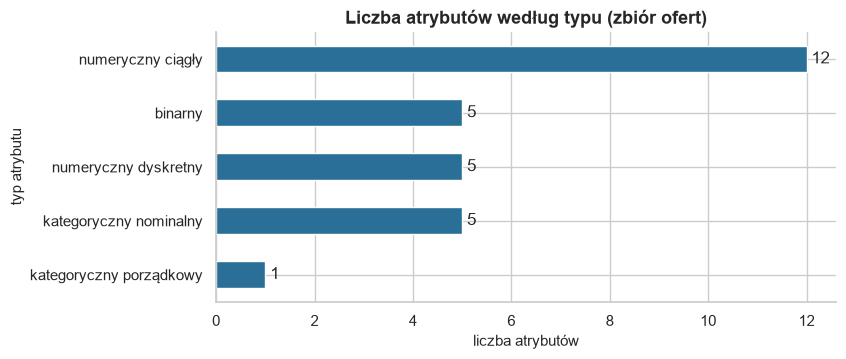

In [5]:
type_counts = attributes["typ atrybutu"].value_counts()
fig, ax = plt.subplots(figsize=(8, 3.5))
type_counts.sort_values().plot(kind="barh", ax=ax, color="#2a6f97")
for i, v in enumerate(type_counts.sort_values()):
    ax.text(v + 0.1, i, str(v), va="center")
ax.set_title("Liczba atrybutów według typu (zbiór ofert)")
ax.set_xlabel("liczba atrybutów")
save_fig(fig, "02_typy_atrybutow")
plt.show()

In [6]:
for col in ["type", "ownership", "buildingMaterial", "condition"]:
    print(f"{col}: {sales[col].value_counts(dropna=False).to_dict()}")

type: {'blockOfFlats': 91368, nan: 42261, 'apartmentBuilding': 32507, 'tenement': 29432}
ownership: {'condominium': 176123, 'cooperative': 19433, 'udział': 12}
buildingMaterial: {'brick': 91899, nan: 77382, 'concreteSlab': 26287}
condition: {nan: 146307, 'premium': 27869, 'low': 21392}


## 2.3 Struktura zbioru kosztów życia

Zbiór 2 występuje w dwóch wariantach: **przekrój 2024** (295 miast) oraz **szereg czasowy 2010–2024** (180 miast × lata).
Wszystkie atrybuty liczbowe są numeryczne ciągłe (kwoty w PLN, wskaźniki); `city`, `voivodeship`, `city_tier`, `powiat_type`, `data_source` są kategoryczne.

In [7]:
cost_attributes = pd.DataFrame({
    "atrybut": cost_2024.columns,
    "typ pandas": cost_2024.dtypes.astype(str).values,
    "typ atrybutu": ["kategoryczny porządkowy" if c == "city_tier" else
                     "numeryczny ciągły" if pd.api.types.is_numeric_dtype(cost_2024[c]) else
                     "kategoryczny nominalny" for c in cost_2024.columns],
    "unikalne": cost_2024.nunique().values,
    "braki": cost_2024.isna().sum().values,
})
cost_attributes

,atrybut,typ pandas,typ atrybutu,unikalne,braki
0,city,str,kategoryczny nominalny,290,0
1,voivodeship,str,kategoryczny nominalny,16,0
2,powiat_type,str,kategoryczny nominalny,2,0
3,city_tier,str,kategoryczny porządkowy,6,0
4,population_approx,int64,numeryczny ciągły,107,0
5,avg_salary_gross_pln,int64,numeryczny ciągły,211,0
6,median_salary_gross_pln,int64,numeryczny ciągły,209,0
7,median_salary_net_pln,int64,numeryczny ciągły,204,0
8,cost_of_living_index,float64,numeryczny ciągły,155,0
9,rent_1br_city_center_pln,int64,numeryczny ciągły,247,0


## 2.4 Wspólne atrybuty i relacje między zbiorami

| Zbiór 1 (oferty) | Zbiór 2 (koszty życia) | Uwagi |
|---|---|---|
| `city` (np. `krakow`) | `city` (np. `Kraków`) | **klucz łączenia** — wymaga standaryzacji (małe litery, bez polskich znaków) |
| `period` (rok-miesiąc oferty) | `year` / `data_year` | wymiar czasowy: oferty 2023-08…2024-06 ↔ płace 2023/2024 |
| `price` (najem) | `rent_1br_city_center_pln`, `rent_1br_outside_center_pln` | ten sam rodzaj informacji z dwóch źródeł — możliwa weryfikacja spójności |

Relacja zbiorów to **wiele-do-jednego**: wiele ofert w danym mieście ↔ jeden wiersz statystyk miasta.
**Uwaga:** w zbiorze kosztów życia nazwa miasta *nie jest unikalna* (homonimy w różnych województwach) — pełny klucz to `(city, voivodeship)`.

In [8]:
dupes = cost_2024[cost_2024["city"].duplicated(keep=False)].sort_values("city")
dupes[["city", "voivodeship", "city_tier", "population_approx", "median_salary_net_pln"]]

,city,voivodeship,city_tier,population_approx,median_salary_net_pln
112,Chrzanów,Małopolskie,city_small,40000,3519
120,Chrzanów,Śląskie,city_small,39000,3929
151,Giżycko,Podlaskie,town,30000,3601
152,Giżycko,Warmińsko-Mazurskie,town,30000,3601
239,Głogów Małopolski,Małopolskie,small_town,15000,3329
241,Głogów Małopolski,Podkarpackie,small_town,15000,3329
173,Kluczbork,Opolskie,town,24000,3492
179,Kluczbork,Śląskie,town,24000,3492
95,Krosno,Małopolskie,city_small,46000,3601
96,Krosno,Podkarpackie,city_small,46000,3601


In [9]:
# Weryfikacja spójności: mediana czynszu z ofert (mieszkania do 45 m²) vs czynsz 1-pok. z Numbeo
small = rent[rent["squareMeters"] <= 45]
rent_check = (small.groupby("city")["price"].median().rename("mediana czynszu z ofert (≤45 m²)").to_frame())
cost_key = cost_2024.assign(key=cost_2024["city"].map(normalize_city)).drop_duplicates("key").set_index("key")
rent_check["czynsz 1-pok. poza centrum (zbiór 2)"] = cost_key["rent_1br_outside_center_pln"]
rent_check["czynsz 1-pok. centrum (zbiór 2)"] = cost_key["rent_1br_city_center_pln"]
rent_check.index = [city_label(c) for c in rent_check.index]
rent_check.round(0)

,mediana czynszu z ofert (≤45 m²),czynsz 1-pok. poza centrum (zbiór 2),czynsz 1-pok. centrum (zbiór 2)
Białystok,"1,800.00",2703,3709
Bydgoszcz,"1,700.00",2850,3888
Częstochowa,"1,700.00",1957,2543
Gdańsk,"2,600.00",2790,3917
Gdynia,"2,300.00",2845,3839
Katowice,"1,900.00",2709,3840
Kraków,"2,600.00",2716,3668
Łódź,"1,771.00",2637,3654
Lublin,"2,125.00",2771,3642
Poznań,"2,100.00",2683,3581


## 2.5 Relacje między atrybutami

Sprawdzamy, jak cena zależy od podstawowych cech mieszkania. Zależności te będą kluczowe przy modelowaniu (etapy 4–5).

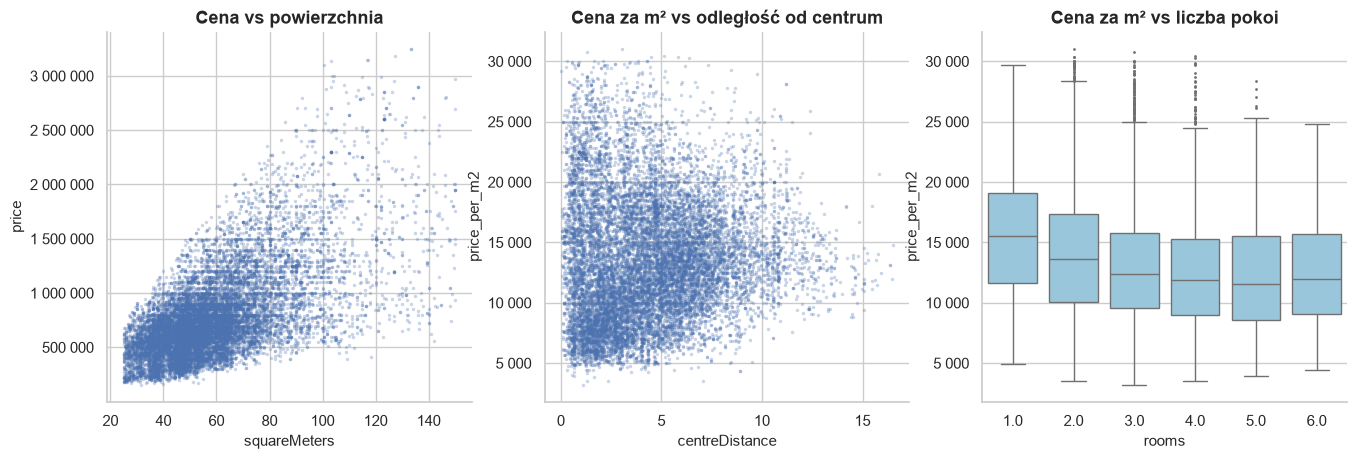

In [10]:
sample = sales.sample(15000, random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
sns.scatterplot(data=sample, x="squareMeters", y="price", s=6, alpha=0.3, ax=axes[0], linewidth=0)
axes[0].set_title("Cena vs powierzchnia")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(thousands))
sns.scatterplot(data=sample, x="centreDistance", y="price_per_m2", s=6, alpha=0.3, ax=axes[1], linewidth=0)
axes[1].set_title("Cena za m² vs odległość od centrum")
sns.boxplot(data=sample, x="rooms", y="price_per_m2", ax=axes[2], color="#8ecae6", fliersize=1)
axes[2].set_title("Cena za m² vs liczba pokoi")
for ax in axes[1:]:
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(thousands))
save_fig(fig, "02_relacje_atrybutow")
plt.show()

In [11]:
num_cols = ["price", "price_per_m2", "squareMeters", "rooms", "floor", "floorCount", "buildYear",
            "centreDistance", "poiCount", "schoolDistance", "restaurantDistance", "collegeDistance"]
corr_preview = sales[num_cols].corr()["price_per_m2"].drop("price_per_m2").sort_values()
corr_preview.to_frame("korelacja z ceną za m² (Pearson)")

,korelacja z ceną za m² (Pearson)
restaurantDistance,-0.18
rooms,-0.13
squareMeters,-0.10
collegeDistance,-0.07
schoolDistance,-0.06
centreDistance,0.07
floor,0.10
floorCount,0.17
buildYear,0.20
poiCount,0.23


**Uwaga — paradoks Simpsona.** W całym zbiorze korelacja ceny za m² z odległością od centrum jest bliska zera (a nawet lekko dodatnia),
bo duże i drogie miasta (Warszawa) mają też największe odległości. Liczymy więc korelację **osobno w każdym mieście**:

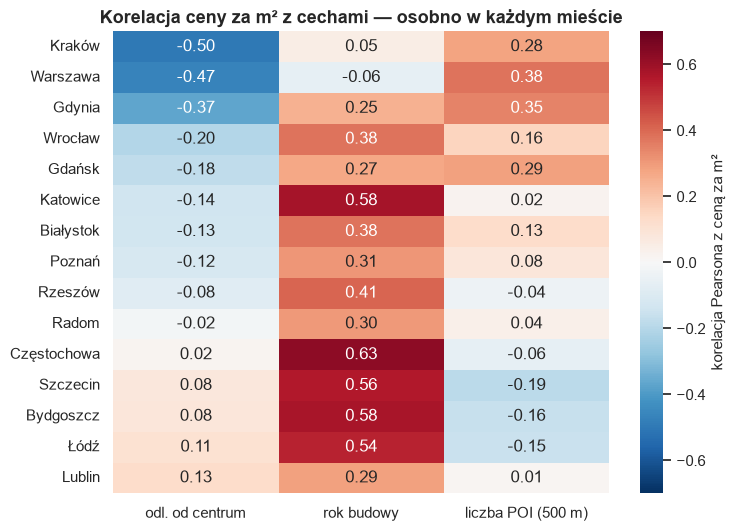

In [12]:
within_city = sales.groupby("city")[["price_per_m2", "centreDistance", "buildYear", "poiCount"]].corr()
within_city = within_city.xs("price_per_m2", level=1)[["centreDistance", "buildYear", "poiCount"]]
within_city.index = [city_label(c) for c in within_city.index]
within_city = within_city.sort_values("centreDistance")

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(within_city, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.7, vmax=0.7, ax=ax,
            cbar_kws={"label": "korelacja Pearsona z ceną za m²"})
ax.set_title("Korelacja ceny za m² z cechami — osobno w każdym mieście")
ax.set_xticklabels(["odl. od centrum", "rok budowy", "liczba POI (500 m)"], rotation=0)
save_fig(fig, "02_korelacje_w_miastach")
plt.show()

- W **dużych miastach** (Kraków, Warszawa, Gdynia, Wrocław) cena wyraźnie **spada z odległością od centrum** i rośnie z liczbą punktów usługowych w okolicy — liczy się lokalizacja.
- W **mniejszych ośrodkach** (Łódź, Bydgoszcz, Szczecin, Częstochowa, Katowice) dominuje **rok budowy** — nowe osiedla powstają na obrzeżach, a w centrum przeważają stare kamienice i bloki.
- W Warszawie rok budowy prawie nie wpływa na cenę (−0,06) — premia za lokalizację przeważa nad wiekiem budynku.

In [13]:
binary_cols = ["hasParkingSpace", "hasBalcony", "hasElevator", "hasSecurity", "hasStorageRoom"]
binary_effect = pd.DataFrame({
    col: sales.groupby(col)["price_per_m2"].median() for col in binary_cols
}).T
binary_effect["różnica yes - no [PLN/m²]"] = binary_effect["yes"] - binary_effect["no"]
binary_effect.round(0)

,no,yes,różnica yes - no [PLN/m²]
hasParkingSpace,"12,698.00","13,666.00",968.00
hasBalcony,"12,927.00","12,997.00",69.00
hasElevator,"11,217.00","14,947.00","3,730.00"
hasSecurity,"12,742.00","14,930.00","2,188.00"
hasStorageRoom,"14,000.00","11,765.00","-2,235.00"


Udogodnienia (winda, ochrona, parking) wiążą się z wyższą ceną za m². Ujemna różnica dla komórki lokatorskiej to przykład **zmiennej zakłócającej** — komórki mają głównie starsze bloki z wielkiej płyty, tańsze z innych powodów.

## 2.6 Podstawowa analiza statystyczna

Miary położenia (średnia, mediana, kwartyle), rozproszenia (odchylenie standardowe, IQR, współczynnik zmienności) oraz kształtu rozkładu (skośność, kurtoza).

In [14]:
def describe_ext(df: pd.DataFrame, cols) -> pd.DataFrame:
    d = df[cols].describe().T
    d["mediana"] = df[cols].median()
    d["IQR"] = d["75%"] - d["25%"]
    d["wsp. zmienności [%]"] = d["std"] / d["mean"] * 100
    d["skośność"] = df[cols].skew()
    d["kurtoza"] = df[cols].kurt()
    return d

describe_ext(sales, ["price", "price_per_m2", "squareMeters", "rooms", "buildYear", "centreDistance", "poiCount"])

,count,mean,std,min,25%,50%,75%,max,mediana,IQR,wsp. zmienności [%],skośność,kurtoza
price,"195,568.00","784,183.30","409,709.23","150,000.00","520,000.00","699,000.00","930,000.00","3,250,000.00","699,000.00","410,000.00",52.25,1.76,4.53
price_per_m2,"195,568.00","13,547.73","5,024.20","3,000.00","9,681.44","12,978.72","16,769.84","32,096.77","12,978.72","7,088.41",37.09,0.59,-0.02
squareMeters,"195,568.00",58.70,21.41,25.00,44.00,54.60,68.55,150.00,54.60,24.55,36.47,1.21,1.85
rooms,"195,568.00",2.68,0.92,1.00,2.00,3.00,3.00,6.00,3.00,1.00,34.15,0.70,0.83
buildYear,"163,352.00","1,985.98",33.81,"1,850.00","1,967.00","1,994.00","2,016.00","2,024.00","1,994.00",49.00,1.70,-0.90,0.09
centreDistance,"195,568.00",4.35,2.84,0.01,2.01,3.98,6.15,16.94,3.98,4.14,65.17,0.77,0.35
poiCount,"195,568.00",20.67,24.33,0.00,7.00,14.00,24.00,212.00,14.00,17.00,117.67,2.93,11.23


In [15]:
describe_ext(rent, ["price", "price_per_m2", "squareMeters", "rooms", "buildYear", "centreDistance"])

,count,mean,std,min,25%,50%,75%,max,mediana,IQR,wsp. zmienności [%],skośność,kurtoza
price,"70,847.00","3,852.80","2,381.54",346.00,"2,500.00","3,100.00","4,490.00","23,000.00","3,100.00","1,990.00",61.81,2.55,8.65
price_per_m2,"70,847.00",69.20,23.35,11.30,53.00,65.96,81.58,189.47,65.96,28.58,33.74,1.03,1.96
squareMeters,"70,847.00",55.25,22.69,25.00,40.00,50.00,64.00,150.00,50.00,24.00,41.06,1.50,2.46
rooms,"70,847.00",2.38,0.87,1.00,2.00,2.00,3.00,6.00,2.00,1.00,36.57,1.11,2.12
buildYear,"51,165.00","1,998.11",30.29,"1,850.00","1,984.00","2,010.00","2,020.00","2,024.00","2,010.00",36.00,1.52,-1.60,1.93
centreDistance,"70,847.00",3.86,2.61,0.02,1.77,3.38,5.42,16.62,3.38,3.65,67.67,0.91,0.62


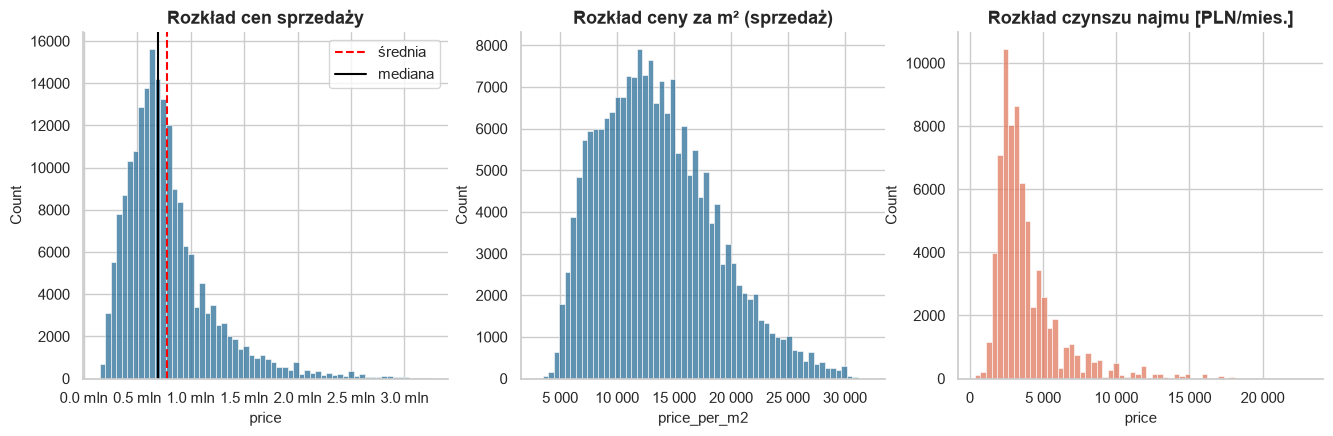

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(sales["price"], bins=60, ax=axes[0], color="#2a6f97")
axes[0].axvline(sales["price"].mean(), color="red", ls="--", label="średnia")
axes[0].axvline(sales["price"].median(), color="black", ls="-", label="mediana")
axes[0].set_title("Rozkład cen sprzedaży")
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e6:.1f} mln"))
axes[0].legend()
sns.histplot(sales["price_per_m2"], bins=60, ax=axes[1], color="#2a6f97")
axes[1].set_title("Rozkład ceny za m² (sprzedaż)")
sns.histplot(rent["price"], bins=60, ax=axes[2], color="#e07a5f")
axes[2].set_title("Rozkład czynszu najmu [PLN/mies.]")
for ax in axes[1:]:
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(thousands))
save_fig(fig, "02_rozklady_cen")
plt.show()

Rozkłady cen są **prawostronnie skośne** (średnia > mediana) — w dalszej analizie jako miarę typową stosujemy **medianę**, odporną na drogie oferty premium.

## 2.7 Porównanie atrybutów między miastami

In [17]:
city_stats = sales.groupby("city").agg(
    ofert=("id", "size"),
    mediana_ceny=("price", "median"),
    mediana_ceny_m2=("price_per_m2", "median"),
    srednia_ceny_m2=("price_per_m2", "mean"),
    std_ceny_m2=("price_per_m2", "std"),
    mediana_metrazu=("squareMeters", "median"),
    mediana_roku_budowy=("buildYear", "median"),
    mediana_odl_centrum=("centreDistance", "median"),
).sort_values("mediana_ceny_m2", ascending=False)
city_stats.index = [city_label(c) for c in city_stats.index]
city_stats

,ofert,mediana_ceny,mediana_ceny_m2,srednia_ceny_m2,std_ceny_m2,mediana_metrazu,mediana_roku_budowy,mediana_odl_centrum
Warszawa,59246,"885,000.00","16,899.91","17,333.49","4,162.70",55.10,"1,999.00",5.85
Kraków,29026,"795,000.00","15,357.14","15,982.91","3,960.35",52.00,"2,007.00",3.95
Gdańsk,19210,"749,000.00","13,421.88","14,536.35","4,222.79",56.00,"2,009.00",5.15
Wrocław,20200,"685,000.00","12,413.79","12,897.10","2,844.49",55.37,"2,000.00",3.01
Gdynia,8164,"696,000.00","11,891.42","12,850.46","4,249.42",60.00,"1,996.00",4.21
Poznań,7705,"599,000.00","10,581.40","10,772.46","2,152.67",57.00,"1,994.00",3.24
Rzeszów,1801,"540,000.00","10,000.00","10,009.45","2,055.39",56.45,"2,011.00",2.22
Lublin,5704,"530,000.00","9,167.66","9,339.17","1,728.38",58.08,"1,987.00",2.66
Białystok,2464,"450,000.00","8,947.37","9,165.60","1,886.39",52.00,"1,988.00",2.04
Szczecin,6331,"519,000.00","8,578.95","8,874.51","2,272.32",61.31,"1,975.00",2.86


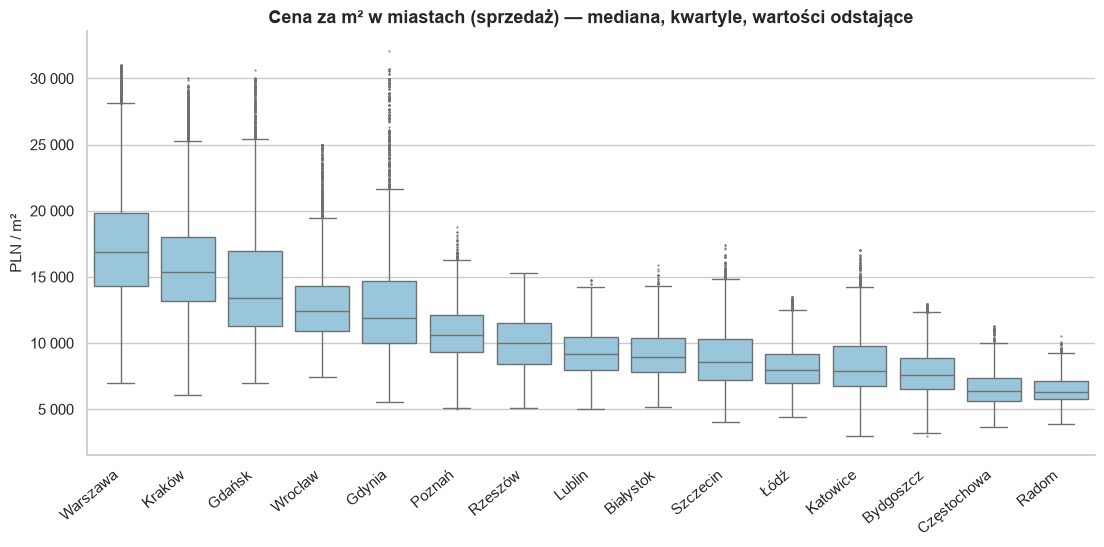

In [18]:
order = sales.groupby("city")["price_per_m2"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(13, 5.5))
sns.boxplot(data=sales, x="city", y="price_per_m2", order=order, ax=ax, color="#8ecae6", fliersize=0.5)
ax.set_xticks(range(len(order)), [city_label(c) for c in order], rotation=40, ha="right")
ax.set_title("Cena za m² w miastach (sprzedaż) — mediana, kwartyle, wartości odstające")
ax.set_xlabel("")
ax.set_ylabel("PLN / m²")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(thousands))
save_fig(fig, "02_cena_m2_miasta_boxplot")
plt.show()

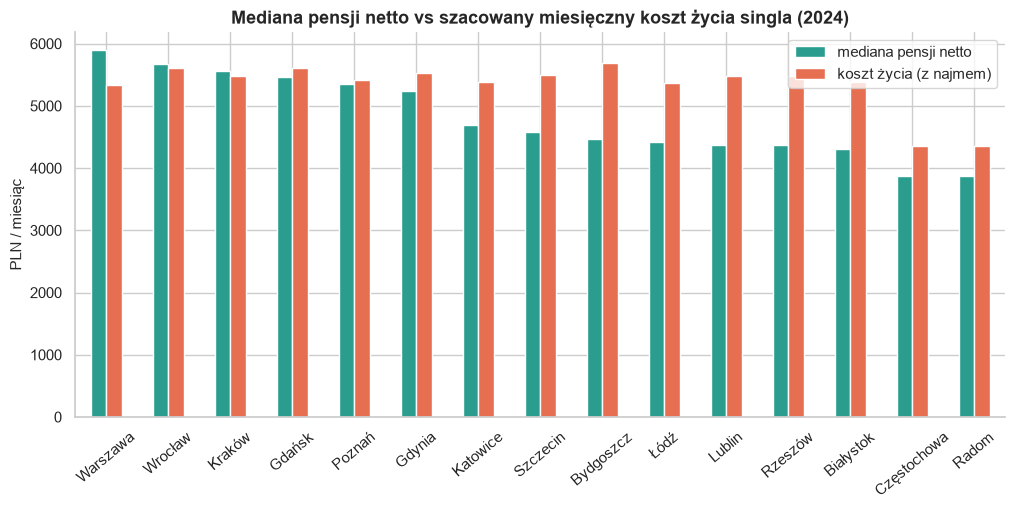

In [19]:
big15 = cost_2024.assign(key=cost_2024["city"].map(normalize_city))
big15 = big15[big15["key"].isin(CITY_LABELS)].drop_duplicates("key").set_index("city")
cols = ["median_salary_net_pln", "est_monthly_cost_single_pln"]
fig, ax = plt.subplots(figsize=(12, 5))
big15.sort_values("median_salary_net_pln", ascending=False)[cols].plot(kind="bar", ax=ax, color=["#2a9d8f", "#e76f51"])
ax.set_title("Mediana pensji netto vs szacowany miesięczny koszt życia singla (2024)")
ax.set_xlabel("")
ax.set_ylabel("PLN / miesiąc")
ax.legend(["mediana pensji netto", "koszt życia (z najmem)"])
ax.tick_params(axis="x", rotation=40)
save_fig(fig, "02_pensje_vs_koszty")
plt.show()

## 2.8 Techniki imputacji brakujących wartości

Najwięcej braków mają: `condition` (~75%), `buildingMaterial` (~40%), `type` (~22%), `floor` (~18%) i `buildYear` (~17%).

Porównujemy trzy techniki imputacji dla atrybutu **`buildYear`** (ważny predyktor ceny):
1. **średnia**, 2. **mediana**, 3. **regresja** (model przewiduje rok budowy na podstawie innych cech).

Aby ocenić jakość, *sztucznie ukrywamy* 20% znanych wartości, uzupełniamy je każdą metodą i mierzymy błąd względem prawdy (MAE).

In [20]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

known = sales.drop_duplicates("id", keep="last").dropna(subset=["buildYear"]).copy()
known["type_code"] = known["type"].astype("category").cat.codes
features = ["floorCount", "centreDistance", "poiCount", "price_per_m2", "squareMeters", "latitude", "longitude", "type_code"]
known = known.dropna(subset=features)

train, test = train_test_split(known, test_size=0.2, random_state=RANDOM_STATE)
truth = test["buildYear"]

results = {
    "średnia": np.full(len(test), train["buildYear"].mean()),
    "mediana": np.full(len(test), train["buildYear"].median()),
    "mediana w grupie (miasto)": test["city"].map(train.groupby("city")["buildYear"].median()),
    "regresja liniowa": LinearRegression().fit(train[features], train["buildYear"]).predict(test[features]),
    "regresja (las losowy)": RandomForestRegressor(n_estimators=60, max_depth=14, n_jobs=-1, random_state=RANDOM_STATE)
                              .fit(train[features], train["buildYear"]).predict(test[features]),
}
imputation_eval = pd.DataFrame({
    "MAE [lata]": {k: mean_absolute_error(truth, v) for k, v in results.items()},
    "średnia po imputacji": {k: np.mean(v) for k, v in results.items()},
    "odch. std po imputacji": {k: np.std(v) for k, v in results.items()},
}).sort_values("MAE [lata]")
print(f"Prawdziwe wartości: średnia={truth.mean():.1f}, odch. std={truth.std():.1f}")
imputation_eval

Prawdziwe wartości: średnia=1987.6, odch. std=31.4


,MAE [lata],średnia po imputacji,odch. std po imputacji
regresja (las losowy),8.70,"1,987.38",27.94
regresja liniowa,19.13,"1,987.36",19.73
mediana w grupie (miasto),24.74,"1,996.22",9.30
mediana,25.86,"1,993.00",0.00
średnia,26.16,"1,986.99",0.00


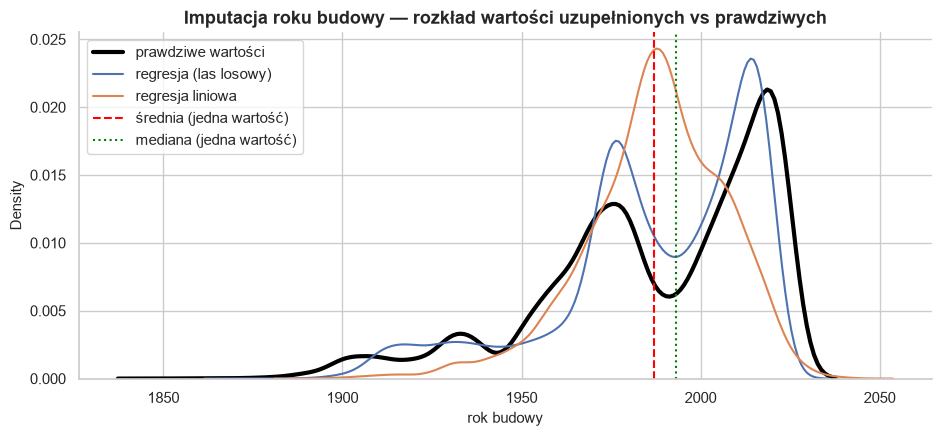

In [21]:
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.kdeplot(truth, ax=ax, label="prawdziwe wartości", lw=3, color="black")
sns.kdeplot(results["regresja (las losowy)"], ax=ax, label="regresja (las losowy)")
sns.kdeplot(results["regresja liniowa"], ax=ax, label="regresja liniowa")
ax.axvline(results["średnia"][0], color="red", ls="--", label="średnia (jedna wartość)")
ax.axvline(results["mediana"][0], color="green", ls=":", label="mediana (jedna wartość)")
ax.set_title("Imputacja roku budowy — rozkład wartości uzupełnionych vs prawdziwych")
ax.set_xlabel("rok budowy")
ax.legend()
save_fig(fig, "02_imputacja_porownanie")
plt.show()

**Wnioski z porównania imputacji:**
- Średnia i mediana wstawiają **jedną stałą wartość** — spłaszczają rozkład (zaniżają wariancję) i dają duży błąd.
- Mediana w grupie (per miasto) jest nieco lepsza, bo uwzględnia lokalną strukturę zabudowy.
- **Imputacja regresyjna** (zwłaszcza las losowy) daje najmniejszy błąd i najlepiej odtwarza rozkład, bo wykorzystuje zależności z innymi atrybutami (lokalizacja, wysokość budynku, cena).
- W etapie 3 dla `buildYear` stosujemy więc imputację **regresyjną**, a dla atrybutów kategorycznych z bardzo dużą liczbą braków (`condition`) — osobną kategorię `brak_danych` (brak informacji sam w sobie niesie treść: ogłoszeniodawca nie chwali się stanem).

## 2.9 Ergonomia wizualizacji — zasady zastosowane w projekcie

- Jeden przekaz na wykres; tytuł mówi, *co* pokazuje wykres, osie są podpisane z jednostkami (PLN, PLN/m², km).
- Separatory tysięcy w liczbach (`1 234 567`), unikanie notacji naukowej.
- Słupki sortowane według wartości — łatwiejsze porównanie; poziome słupki dla długich nazw miast.
- Spójna, stonowana paleta; kolor wyróżnia tylko istotne kategorie (np. sprzedaż vs najem).
- Do rozkładów skośnych: mediana + kwartyle (boxplot) zamiast samej średniej.
- Brak zbędnych elementów (górna i prawa ramka usunięte, delikatna siatka).

## 2.10 Podsumowanie etapu

- Zbiór ofert: **28 atrybutów** — 12 numerycznych ciągłych, 5 numerycznych dyskretnych, 5 kategorycznych nominalnych (w tym `id`), 1 porządkowy (`condition`), 5 binarnych; zbiór kosztów życia — 19 atrybutów, w większości numerycznych.
- Weryfikacja krzyżowa czynszów: mediany czynszów z ofert różnią się od czynszów 1-pokojowych ze zbioru 2 (zbiór 2 zawiera dane częściowo modelowane — `data_source = gus_modeled/numbeo`). Do wskaźników najmu używamy więc **rzeczywistych ofert** (zbiór 1), a ze zbioru 2 bierzemy płace i koszty życia.
- Wspólny atrybut `city` wymaga standaryzacji; w zbiorze 2 klucz musi uwzględniać województwo (homonimy).
- Ceny mają rozkład prawostronnie skośny — miarą typową jest mediana. W dużych miastach cena za m² **maleje** z odległością od centrum, w mniejszych silniej zależy od roku budowy; udogodnienia (winda, ochrona, parking) podnoszą cenę. Ujemny „efekt” komórki lokatorskiej to zmienna zakłócająca — komórki mają głównie starsze bloki.
- Porównanie imputacji wykazało przewagę metody regresyjnej nad średnią/medianą.